In [1]:
!pip -q install plotly

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown

np.random.seed(42)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [2]:
jumlah_data = 120

jenis_tugas = [
    "Login",
    "Melihat Jadwal",
    "Melihat Nilai",
    "Mengunduh Materi"
]

data = pd.DataFrame({
    "ID_Pengguna": [
        f"U{i+1:03d}" for i in range(jumlah_data)
    ],
    "Perangkat": np.random.choice(
        ["Desktop", "Mobile", "Tablet"],
        jumlah_data,
        p=[0.30, 0.55, 0.15]
    ),
    "Tugas": np.random.choice(
        jenis_tugas,
        jumlah_data
    )
})

# Waktu pengerjaan dalam detik
waktu_dasar = {
    "Login": 25,
    "Melihat Jadwal": 35,
    "Melihat Nilai": 40,
    "Mengunduh Materi": 55
}

data["Waktu_Pengerjaan"] = [
    max(
        5,
        np.random.normal(waktu_dasar[tugas], 10)
        + (12 if perangkat == "Mobile" else 0)
    )
    for tugas, perangkat in zip(
        data["Tugas"], data["Perangkat"]
    )
]

# Simulasi keberhasilan tugas
data["Berhasil"] = np.random.choice(
    ["Ya", "Tidak"],
    jumlah_data,
    p=[0.82, 0.18]
)

# Skala kepuasan 1 sampai 5
data["Kepuasan"] = np.random.choice(
    [1, 2, 3, 4, 5],
    jumlah_data,
    p=[0.05, 0.10, 0.20, 0.35, 0.30]
)

data["Waktu_Pengerjaan"] = (
    data["Waktu_Pengerjaan"].round(1)
)

print("Jumlah sesi pengujian:", len(data))
display(data.head(10))

Jumlah sesi pengujian: 120


,ID_Pengguna,Perangkat,Tugas,Waktu_Pengerjaan,Berhasil,Kepuasan
0,U001,Mobile,Melihat Jadwal,39.2,Ya,5
1,U002,Tablet,Melihat Nilai,36.8,Ya,4
2,U003,Mobile,Mengunduh Materi,75.1,Ya,4
3,U004,Mobile,Login,24.7,Ya,5
4,U005,Desktop,Melihat Nilai,42.3,Ya,2
5,U006,Desktop,Melihat Jadwal,48.1,Ya,4
6,U007,Desktop,Login,8.9,Tidak,1
7,U008,Tablet,Login,26.8,Ya,4
8,U009,Mobile,Login,39.6,Ya,2
9,U010,Mobile,Melihat Nilai,59.8,Ya,2


In [3]:
tingkat_keberhasilan = (
    data["Berhasil"].eq("Ya").mean() * 100
)

rata_waktu = data["Waktu_Pengerjaan"].mean()
rata_kepuasan = data["Kepuasan"].mean()

print("RINGKASAN EVALUASI USABILITY")
print("-" * 35)
print(f"Tingkat keberhasilan : {tingkat_keberhasilan:.1f}%")
print(f"Rata-rata waktu      : {rata_waktu:.1f} detik")
print(f"Rata-rata kepuasan   : {rata_kepuasan:.2f} dari 5")

RINGKASAN EVALUASI USABILITY
-----------------------------------
Tingkat keberhasilan : 81.7%
Rata-rata waktu      : 46.5 detik
Rata-rata kepuasan   : 3.85 dari 5


DASHBOARD EVALUASI USABILITY
Jumlah sesi: 120
Keberhasilan tugas: 81.7%
Rata-rata waktu: 46.5 detik
Rata-rata kepuasan: 3.85/5


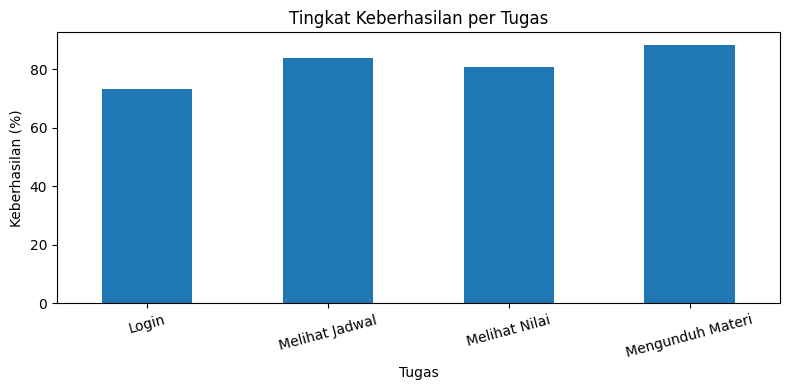

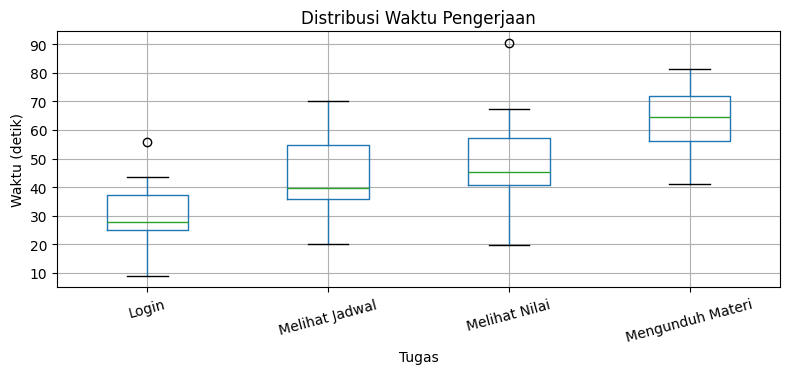

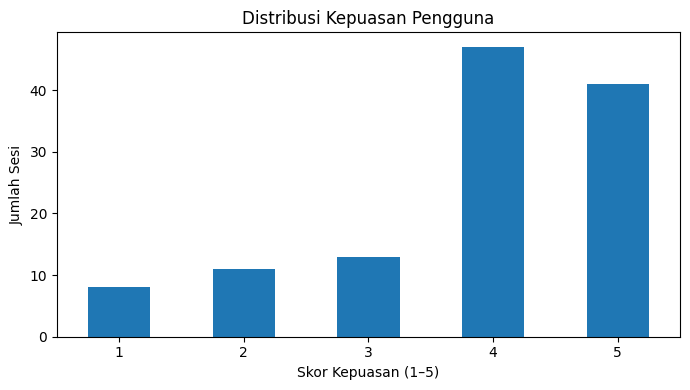

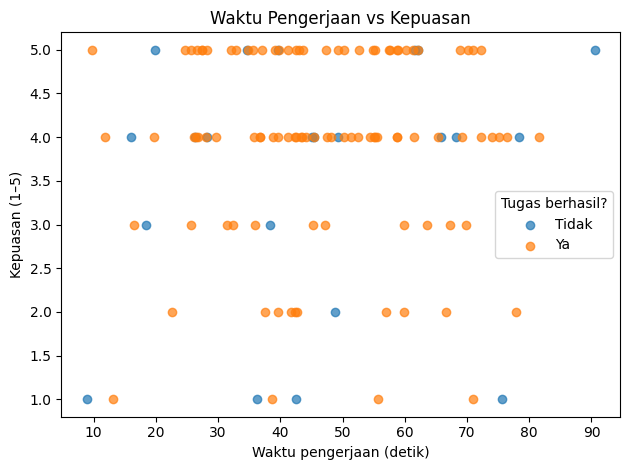

In [7]:

import matplotlib.pyplot as plt
import pandas as pd

# Pastikan dataset tersedia
assert "data" in globals(), "Jalankan bagian 2 terlebih dahulu!"

# Ringkasan
tingkat_berhasil = (data["Berhasil"] == "Ya").mean() * 100
rata_waktu = data["Waktu_Pengerjaan"].mean()
rata_kepuasan = data["Kepuasan"].mean()

print("DASHBOARD EVALUASI USABILITY")
print(f"Jumlah sesi: {len(data)}")
print(f"Keberhasilan tugas: {tingkat_berhasil:.1f}%")
print(f"Rata-rata waktu: {rata_waktu:.1f} detik")
print(f"Rata-rata kepuasan: {rata_kepuasan:.2f}/5")

# Grafik 1: keberhasilan setiap tugas
ringkasan = data.assign(
    Sukses=(data["Berhasil"] == "Ya").astype(int)
).groupby("Tugas")["Sukses"].mean() * 100

ringkasan.plot(kind="bar", figsize=(8, 4))
plt.title("Tingkat Keberhasilan per Tugas")
plt.ylabel("Keberhasilan (%)")
plt.xlabel("Tugas")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Grafik 2: distribusi waktu pengerjaan
data.boxplot(column="Waktu_Pengerjaan", by="Tugas", figsize=(8, 4))
plt.title("Distribusi Waktu Pengerjaan")
plt.suptitle("")
plt.ylabel("Waktu (detik)")
plt.xlabel("Tugas")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Grafik 3: kepuasan pengguna
data["Kepuasan"].value_counts().sort_index().plot(
    kind="bar", figsize=(7, 4)
)
plt.title("Distribusi Kepuasan Pengguna")
plt.xlabel("Skor Kepuasan (1–5)")
plt.ylabel("Jumlah Sesi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Grafik 4: waktu vs kepuasan
for status, grup in data.groupby("Berhasil"):
    plt.scatter(
        grup["Waktu_Pengerjaan"],
        grup["Kepuasan"],
        label=status,
        alpha=0.7
    )

plt.title("Waktu Pengerjaan vs Kepuasan")
plt.xlabel("Waktu pengerjaan (detik)")
plt.ylabel("Kepuasan (1–5)")
plt.legend(title="Tugas berhasil?")
plt.tight_layout()
plt.show()


,Jumlah_Sesi,Keberhasilan,Rata_Waktu,Rata_Kepuasan
Perangkat,,,,
Desktop,41,85.37,41.16,3.88
Mobile,62,79.03,53.28,3.82
Tablet,17,82.35,34.88,3.88


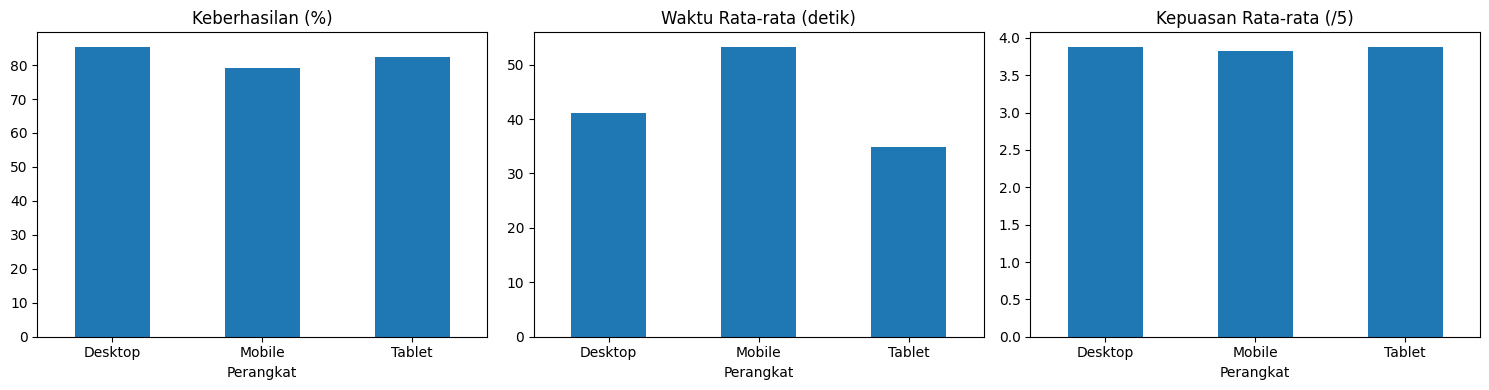

In [8]:

import matplotlib.pyplot as plt
import pandas as pd

ringkasan_perangkat = data.groupby("Perangkat").agg(
    Jumlah_Sesi=("ID_Pengguna", "count"),
    Keberhasilan=("Berhasil", lambda x: (x == "Ya").mean() * 100),
    Rata_Waktu=("Waktu_Pengerjaan", "mean"),
    Rata_Kepuasan=("Kepuasan", "mean")
).round(2)

display(ringkasan_perangkat)

# Visualisasi perbandingan perangkat
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ringkasan_perangkat["Keberhasilan"].plot(
    kind="bar", ax=axes[0], title="Keberhasilan (%)"
)
ringkasan_perangkat["Rata_Waktu"].plot(
    kind="bar", ax=axes[1], title="Waktu Rata-rata (detik)"
)
ringkasan_perangkat["Rata_Kepuasan"].plot(
    kind="bar", ax=axes[2], title="Kepuasan Rata-rata (/5)"
)

for ax in axes:
    ax.set_xlabel("Perangkat")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


In [9]:
hasil_tugas = data.assign(
    Sukses=(data["Berhasil"] == "Ya").astype(int)
).groupby("Tugas").agg(
    Keberhasilan=("Sukses", "mean"),
    Waktu_Rata=("Waktu_Pengerjaan", "mean"),
    Kepuasan_Rata=("Kepuasan", "mean")
)

hasil_tugas["Keberhasilan"] *= 100

print("REKOMENDASI EVALUASI ANTARMUKA")
print("=" * 40)

for tugas, hasil in hasil_tugas.iterrows():
    print(f"\nTugas: {tugas}")
    print(f"Keberhasilan: {hasil['Keberhasilan']:.1f}%")
    print(f"Waktu rata-rata: {hasil['Waktu_Rata']:.1f} detik")
    print(f"Kepuasan rata-rata: {hasil['Kepuasan_Rata']:.2f}/5")

    if hasil["Keberhasilan"] < 80:
        print("Saran: tinjau alur tugas, navigasi, dan kejelasan tombol.")
    elif hasil["Kepuasan_Rata"] < 3.5:
        print("Saran: evaluasi tampilan dan kenyamanan pengguna.")
    else:
        print("Saran: pertahankan desain, lalu uji kembali dengan pengguna.")


REKOMENDASI EVALUASI ANTARMUKA

Tugas: Login
Keberhasilan: 73.3%
Waktu rata-rata: 29.0 detik
Kepuasan rata-rata: 3.43/5
Saran: tinjau alur tugas, navigasi, dan kejelasan tombol.

Tugas: Melihat Jadwal
Keberhasilan: 84.0%
Waktu rata-rata: 42.9 detik
Kepuasan rata-rata: 4.16/5
Saran: pertahankan desain, lalu uji kembali dengan pengguna.

Tugas: Melihat Nilai
Keberhasilan: 80.6%
Waktu rata-rata: 47.7 detik
Kepuasan rata-rata: 3.87/5
Saran: pertahankan desain, lalu uji kembali dengan pengguna.

Tugas: Mengunduh Materi
Keberhasilan: 88.2%
Waktu rata-rata: 63.5 detik
Kepuasan rata-rata: 3.97/5
Saran: pertahankan desain, lalu uji kembali dengan pengguna.


In [10]:
keberhasilan_total = (data["Berhasil"] == "Ya").mean() * 100
waktu_total = data["Waktu_Pengerjaan"].mean()
kepuasan_total = data["Kepuasan"].mean()

print("KESIMPULAN IMPLEMENTASI")
print("=" * 40)

print(
    f"Dari {len(data)} sesi simulasi, tingkat keberhasilan tugas "
    f"adalah {keberhasilan_total:.1f}%."
)
print(f"Rata-rata waktu pengerjaan adalah {waktu_total:.1f} detik.")
print(f"Rata-rata kepuasan pengguna adalah {kepuasan_total:.2f}/5.")

tugas_prioritas = hasil_tugas["Keberhasilan"].idxmin()
print(f"Tugas yang perlu ditinjau terlebih dahulu: {tugas_prioritas}.")

print(
    "\nCatatan: hasil ini berasal dari data simulasi. "
    "Evaluasi usability yang nyata memerlukan partisipasi pengguna."
)


KESIMPULAN IMPLEMENTASI
Dari 120 sesi simulasi, tingkat keberhasilan tugas adalah 81.7%.
Rata-rata waktu pengerjaan adalah 46.5 detik.
Rata-rata kepuasan pengguna adalah 3.85/5.
Tugas yang perlu ditinjau terlebih dahulu: Login.

Catatan: hasil ini berasal dari data simulasi. Evaluasi usability yang nyata memerlukan partisipasi pengguna.
